In [1]:
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
import seaborn as sns


In [2]:
from pathlib import Path
counts_list=[]
root_dir=Path(r'C:\Users\electric\Desktop\GSE69965_RAW')
fig_dir = Path(root_dir) / "figures"
fig_dir.mkdir(exist_ok=True)
file={
    'control1': root_dir/'GSM1714078_zebrafish_28_gill_1.count.txt.gz',
    'control2':root_dir/'GSM1714079_zebrafish_28_gill_2.count.txt.gz',
    'control3':root_dir/'GSM1714080_zebrafish_28_gill_3.count.txt.gz',
    'cold1':root_dir/'GSM1714083_zebrafish_LOE_12h_gill_1.count.txt.gz',
    'cold2':root_dir/'GSM1714084_zebrafish_LOE_12h_gill_2.count.txt.gz',
    'cold3':root_dir/'GSM2176256_AZ5.count.txt.gz'
}
for sample,path in file.items():
    df=pd.read_csv(path,sep='\t',header=None,names=['gene_id','counts'])
    s=df.groupby('gene_id')['counts'].sum().rename(sample)
    counts_list.append(s)
counts=pd.concat(counts_list,axis=1)
counts=counts.dropna().astype(int)
counts=counts[~counts.index.str.startswith('__')]
min_expression_samples=3
counts=counts[(counts>0).sum(axis=1)>=min_expression_samples]
metadata=pd.DataFrame({'condition':['control']*3+['cold']*3},index=counts.columns)
print(counts.shape)
print(metadata.shape)
print(counts.head())

(25329, 6)
(6, 1)
                    control1  control2  control3  cold1  cold2  cold3
gene_id                                                              
ENSDARG00000000001        82        77        86     36     49     67
ENSDARG00000000002       251       301       216    279    214    193
ENSDARG00000000018       325       337       468    662    644    551
ENSDARG00000000019      1238      1081      1543    546    565    743
ENSDARG00000000068       327       319       399    148    187    206


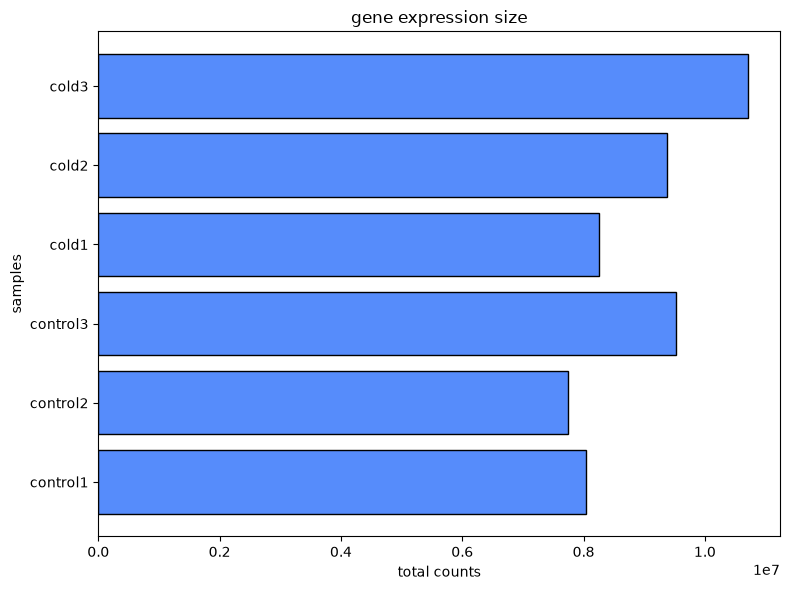

In [3]:
df=pd.DataFrame(counts.sum(axis=0),index=counts.columns,columns=['library_size'])
plt.figure(figsize=(8,6))
plt.barh(df.index,df.library_size,alpha=1,edgecolor='k',height=0.8)
plt.title("gene expression size")
plt.xlabel("total counts")
plt.ylabel("samples")
plt.tight_layout()
plt.show()

                PC1        PC2 condition
control1  32.620860  -0.583454   control
control2  32.881831   5.642190   control
control3  35.398787   3.262132   control
cold1    -26.964153 -26.086831      cold
cold2    -30.803443 -17.766002      cold
cold3    -43.133883  35.531965      cold
可解释方差: [0.57790491 0.19179086]


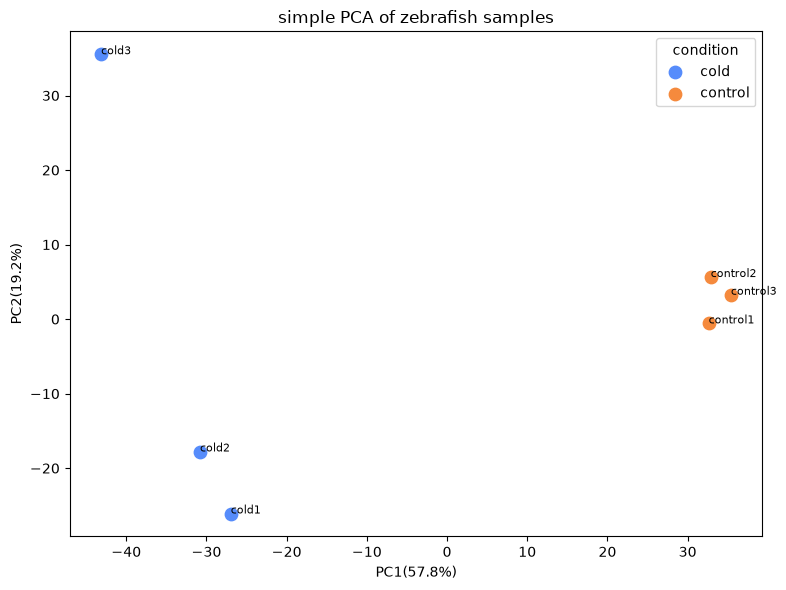

In [4]:
X=counts.T
X=np.log1p(X)
top=X.var(axis=0).sort_values(ascending=False).head(2000).index
X_top=X[top]
X_scaled=StandardScaler().fit_transform(X_top)
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
pca_df=pd.DataFrame(X_pca,index=X_top.index,columns=['PC1','PC2'])
pca_df['condition']=metadata.loc[pca_df.index,'condition']
print(pca_df)
print("可解释方差:",pca.explained_variance_ratio_)
plt.figure(figsize=(8,6))
for cond, group in pca_df.groupby("condition"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        s=80,
        label=cond
    )
for sample, row in pca_df.iterrows():
    plt.annotate(
        sample,
        (row["PC1"], row["PC2"]),
        fontsize=8,
    )
plt.xlabel(f'PC1({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title("simple PCA of zebrafish samples")
plt.legend(title="condition")
plt.savefig(root_dir/'figures'/"simple PCA of zebrafish samples.png",dpi=300)
plt.tight_layout()
plt.show()

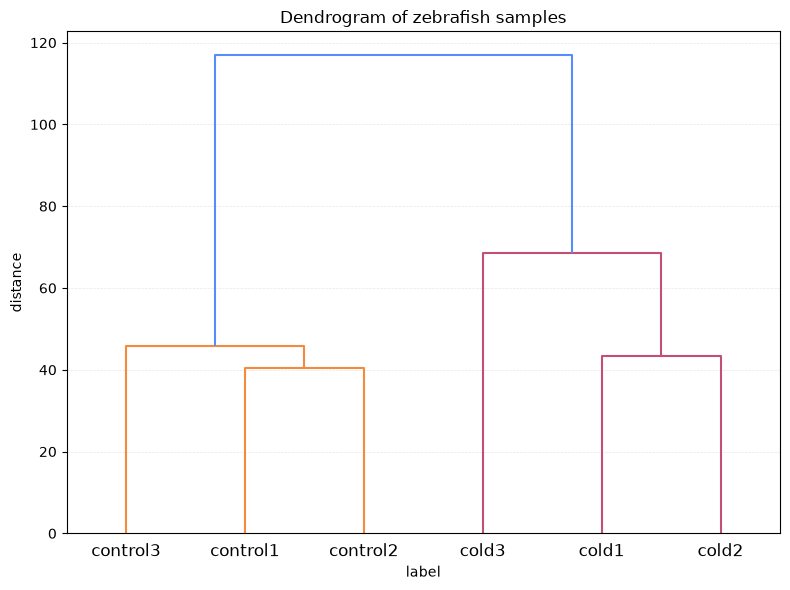

In [5]:
model=AgglomerativeClustering(n_clusters=2,metric='euclidean',linkage='ward')
labels=model.fit_predict(X_scaled)
Z=linkage(X_scaled,method='ward',metric='euclidean')
plt.figure(figsize=(8,6))
dendrogram(Z,labels=X_top.index)
plt.title("Dendrogram of zebrafish samples")
plt.xlabel('label')
plt.ylabel('distance')
plt.grid(axis='y',ls="--",alpha=0.3)
plt.tight_layout()
plt.show()

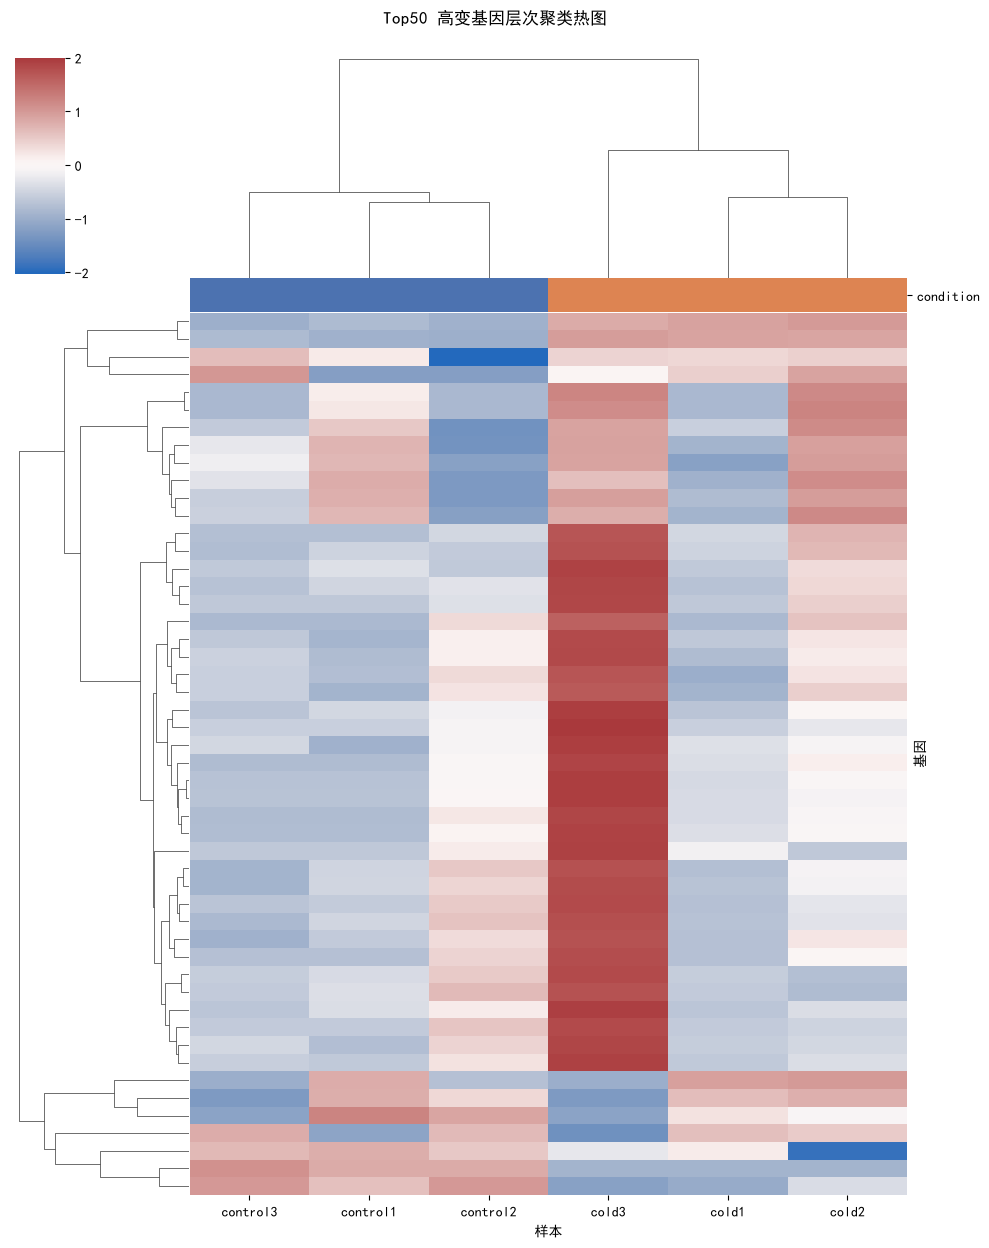

In [19]:
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
top50 = X_top.var(axis=0).sort_values(ascending=False).head(50).index
heat=X_top[top50].T
col_colors = metadata.loc[heat.columns, "condition"].map({
    "control": "#4C72B0",
    "cold": "#DD8452"})
g=sns.clustermap(
    heat,
    col_linkage=Z,
    col_cluster=True,
    z_score=0,
    cmap="vlag",
    center=0,
    figsize=(10,12),
    yticklabels=False,
    col_colors=col_colors,
)
g.fig.suptitle("Top50 高变基因层次聚类热图", y=1.02)
g.ax_heatmap.set_xlabel("样本")
g.ax_heatmap.set_ylabel("基因")
g.savefig(root_dir/'figures'/'Top50 高变基因层次聚类热图.png')
plt.show()

In [7]:
dds=DeseqDataSet(counts=counts.T,metadata=metadata,design='~condition',n_cpus=4)
dds.deseq2()
stat=DeseqStats(dds,contrast=['condition','cold','control'])
stat.summary()
res=stat.results_df
res.to_csv(root_dir/"zebrafish_cold_de.csv")
print(res.head())

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.86 seconds.

Fitting dispersion trend curve...
... done in 0.36 seconds.

Fitting MAP dispersions...
... done in 3.31 seconds.

Fitting LFCs...
... done in 2.15 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 4.33 seconds.



Log2 fold change & Wald test p-value: condition cold vs control
                      baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                              
ENSDARG00000000001   64.857029       -0.563339  0.306337 -1.838952   
ENSDARG00000000002  242.841516       -0.039152  0.269193 -0.145442   
ENSDARG00000000018  499.480543        0.869129  0.183114  4.746392   
ENSDARG00000000019  925.082976       -0.917076  0.170614 -5.375158   
ENSDARG00000000068  257.625431       -0.814186  0.186014 -4.377015   
...                        ...             ...       ...       ...   
ENSDARG00000098046   25.541729        0.412323  0.495326  0.832426   
ENSDARG00000098049    1.167647        1.463365  1.873404  0.781126   
ENSDARG00000098050    1.762455        0.482859  1.822218  0.264984   
ENSDARG00000098051   21.233641        1.531821  0.472313  3.243233   
ENSDARG00000098052    1.645272        1.403645  1.824696  0.769249   

                         

In [8]:
print("结果形状:",res.shape)
print("列名",res.columns)
print(res.head())
print('padj<0.05的基因数',(res.padj<0.05).sum())
top=res.sort_values('padj').head()
print(top)
sig = res[(res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)].copy()
sig = sig.sort_values("padj")
sig.to_csv(r"C:\Users\electric\Desktop\GSE69965_RAW\zebrafish_cold_significant.csv")
print("显著基因数:", sig.shape)
print(sig.head())

结果形状: (25329, 6)
列名 Index(['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj'], dtype='str')
                      baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                              
ENSDARG00000000001   64.857029       -0.563339  0.306337 -1.838952   
ENSDARG00000000002  242.841516       -0.039152  0.269193 -0.145442   
ENSDARG00000000018  499.480543        0.869129  0.183114  4.746392   
ENSDARG00000000019  925.082976       -0.917076  0.170614 -5.375158   
ENSDARG00000000068  257.625431       -0.814186  0.186014 -4.377015   

                          pvalue      padj  
gene_id                                     
ENSDARG00000000001  6.592229e-02  0.144034  
ENSDARG00000000002  8.843621e-01  0.930366  
ENSDARG00000000018  2.070771e-06  0.000021  
ENSDARG00000000019  7.651576e-08  0.000001  
ENSDARG00000000068  1.203157e-05  0.000099  
padj<0.05的基因数 7696
                       baseMean  log2FoldChange     lfcSE       stat 

In [9]:
Path(r'C:\Users\electric\Desktop\GSE69965_RAW\figures').mkdir(exist_ok=True)
plot_df=res.copy()

In [10]:
plot_df['neg_log10_padj']=-np.log10(plot_df.padj.clip(lower=1e-300))
sig_mask=((plot_df.padj<0.05)&(plot_df.log2FoldChange.abs()>1))

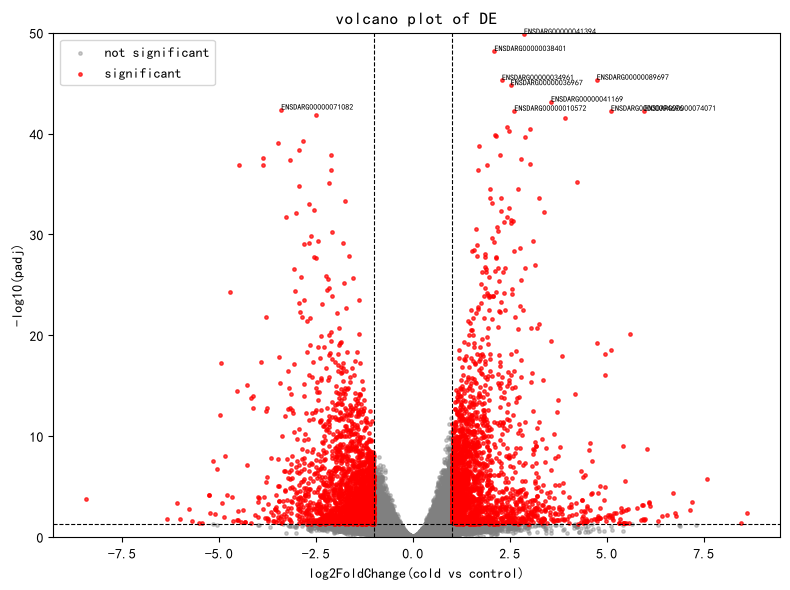

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(plot_df.loc[~sig_mask,'log2FoldChange'],plot_df.loc[~sig_mask,'neg_log10_padj'],s=6,c='grey',alpha=0.4,label='not significant')
plt.scatter(plot_df.loc[sig_mask,'log2FoldChange'],plot_df.loc[sig_mask,'neg_log10_padj'],s=6,c='red',alpha=0.7,label='significant')
plt.axvline(-1,ls='--',c='black',lw=0.8)
plt.axvline(1, ls='--',c='black',lw=0.8)
plt.axhline(-np.log10(0.05),ls='--',c='black',lw=0.8)
plt.xlabel('log2FoldChange(cold vs control)')
plt.ylabel('-log10(padj)')
plt.title("volcano plot of DE")
plt.ylim(0,50)
plt.legend()
plt.tight_layout()
top = plot_df[sig_mask].query("neg_log10_padj <= 50"). sort_values("padj").head(10)
for gene, row in top.iterrows():
    plt.annotate(
        gene,
        (row["log2FoldChange"], row["neg_log10_padj"]),
        fontsize=6,
    )
plt.savefig(root_dir/'figures'/'volcano plot of DE.png')
plt.show()

In [12]:
up=sig[sig['log2FoldChange']>0]
down=sig[sig['log2FoldChange']<0]
print('显著差异基因总数:',sig.shape[0])
print('cold 上调:',up.shape[0])
print('cold 下调:',down.shape[0])

显著差异基因总数: 3986
cold 上调: 1946
cold 下调: 2040


In [13]:
from gprofiler import GProfiler
gp=GProfiler(return_dataframe=True)
genes=[g.split('.')[0] for g in sig.index]
enr=gp.profile(organism='drerio',query=genes)
print('富集结果:',enr.shape)
print(enr.head())
enr=enr.sort_values('p_value')
enr.to_csv(root_dir/"zebrafish_cold_significant_enrichment.csv",index=False)


富集结果: (57, 14)
  source       native                                               name  \
0  GO:CC   GO:0005737                                          cytoplasm   
1  GO:BP   GO:0002376                              immune system process   
2  GO:BP   GO:0080090            regulation of primary metabolic process   
3     TF  TF:M00615_1  Factor: c-Myc:Max; motif: NNNNNNNCACGTGNNNNNNN...   
4     TF    TF:M00615     Factor: c-Myc:Max; motif: NNNNNNNCACGTGNNNNNNN   

        p_value  significant  \
0  1.252565e-07         True   
1  6.749641e-07         True   
2  4.032118e-06         True   
3  5.813476e-06         True   
4  5.813476e-06         True   

                                         description  term_size  query_size  \
0  "The contents of a cell excluding the plasma m...       2445        1068   
1  "Any process involved in the development or fu...        405        1486   
2  "Any process that modulates the frequency, rat...       1701        1486   
3  Factor: c-Myc:Ma

In [14]:
cols = [
    "source",
    "name",
    "p_value",
    "intersection_size",
    "query_size",
    "term_size",
]

print(enr[cols].head(20))

   source                                               name       p_value  \
0   GO:CC                                          cytoplasm  1.252565e-07   
1   GO:BP                              immune system process  6.749641e-07   
2   GO:BP            regulation of primary metabolic process  4.032118e-06   
3      TF  Factor: c-Myc:Max; motif: NNNNNNNCACGTGNNNNNNN...  5.813476e-06   
4      TF     Factor: c-Myc:Max; motif: NNNNNNNCACGTGNNNNNNN  5.813476e-06   
5      TF                  Factor: C-Myc; motif: NGCCACGTGNN  8.913270e-06   
6   GO:BP                                    immune response  1.928972e-05   
7   GO:BP  regulation of nucleobase-containing compound m...  2.583463e-05   
8      TF  Factor: c-Myc:Max; motif: NNACCACGTGGTNN; matc...  3.069238e-05   
9      TF           Factor: c-Myc:Max; motif: NNACCACGTGGTNN  3.069238e-05   
10  GO:MF                            oxidoreductase activity  4.996897e-05   
11  GO:CC                                extracellular space  8.

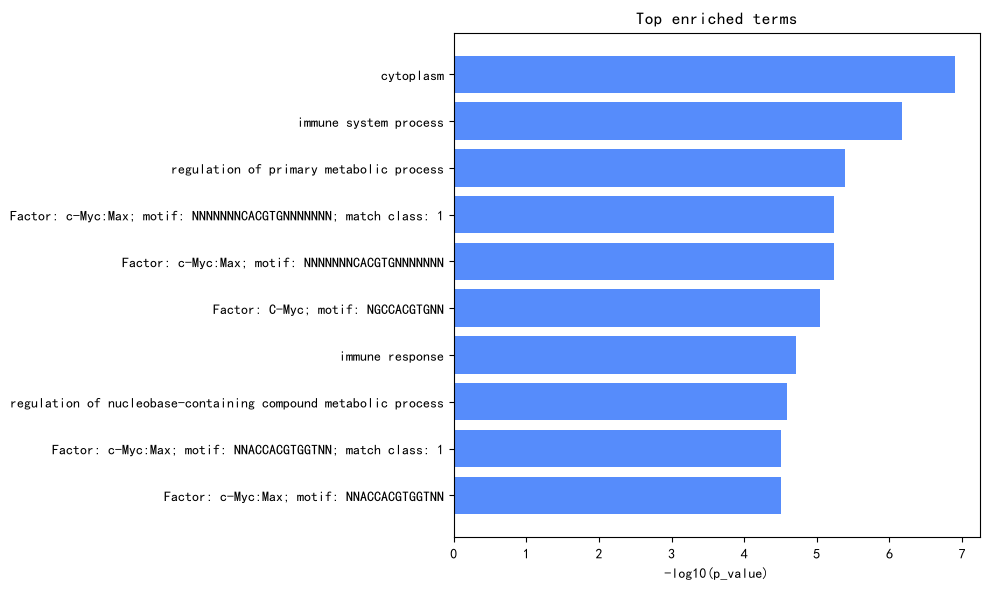

In [15]:
top = enr.sort_values("p_value").head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top["name"], -np.log10(top["p_value"]))
plt.xlabel("-log10(p_value)")
plt.title("Top enriched terms")
plt.tight_layout()
plt.savefig(root_dir/"figures/enrichment_top10.png", dpi=300)
plt.show()

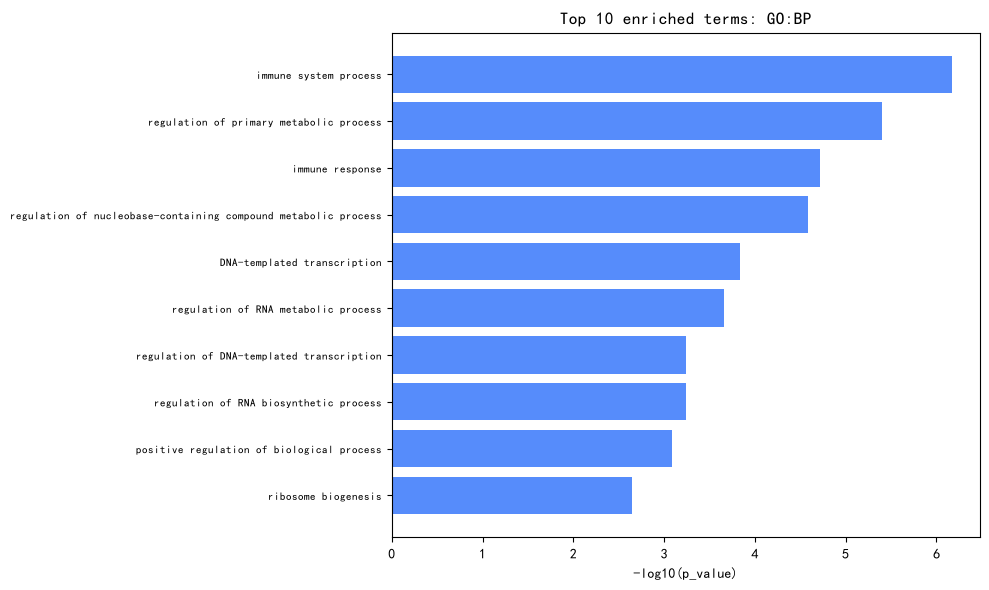

saved: C:\Users\electric\Desktop\GSE69965_RAW\figures\enrichment_GO_BP_top10.png
KEGG: 没有富集结果，跳过


In [16]:
def plot_enrichment(df, source, filename, top_n=10):
    sub = df[df["source"] == source].copy()
    if sub.empty:
        print(f"{source}: 没有富集结果，跳过")
        return
    sub = sub.sort_values("p_value").head(top_n).iloc[::-1]
    plt.figure(figsize=(10, 6))
    plt.barh(sub["name"],-np.log10(sub["p_value"].clip(lower=1e-300)))
    plt.xlabel("-log10(p_value)")
    plt.title(f"Top {len(sub)} enriched terms: {source}")
    plt.yticks(fontsize=8)
    plt.tight_layout()
    out = fig_dir / filename
    plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    print("saved:", out)
plot_enrichment(enr, "GO:BP", "enrichment_GO_BP_top10.png")
plot_enrichment(enr, "KEGG", "enrichment_KEGG_top10.png")